# Phase 2 — Classical Models

## Goal

Build understandable baseline models before neural networks. Every model uses the
same text and labels. We first compare models on a validation portion of the
training data, then refit them on all training rows and evaluate once on the
untouched test set.

The models are:

1. most-frequent dummy baseline;
2. Multinomial Naive Bayes with word TF-IDF;
3. Logistic Regression with word and character TF-IDF;
4. Linear SVM with word and character TF-IDF.

Character n-grams are useful for Roman Urdu because spelling is not standardized.

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"

for folder in [IMAGES, MODELS, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(PROJECT_ROOT / ".cache" / "huggingface")
print("Project folder:", PROJECT_ROOT)

Project folder: E:\AssDS\Project


In [2]:
import time

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
LABEL_NAMES = ["Negative", "Neutral", "Positive"]

## 1. Load the fixed Phase 1 train and test files

In [3]:
train_df = pd.read_csv(DATA / "train.csv")
test_df = pd.read_csv(DATA / "test.csv")

X_train = train_df["model_text"].fillna("")
y_train = train_df["label"]
X_test = test_df["model_text"].fillna("")
y_test = test_df["label"]

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Test data will not be used during model selection.")

Training rows: 15592
Test rows: 3898
Test data will not be used during model selection.


## 2. Create validation data

The validation set comes only from the training file. `stratify` preserves class
percentages, and the test set remains untouched until final evaluation.

In [4]:
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

print("Fit rows:", len(X_fit))
print("Validation rows:", len(X_validation))

Fit rows: 12473
Validation rows: 3119


## 3. Define simple reusable pipelines

In [5]:
word_tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    max_features=30000,
    sublinear_tf=True,
)

word_and_character_tfidf = FeatureUnion(
    [
        (
            "word",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.98,
                max_features=30000,
                sublinear_tf=True,
            ),
        ),
        (
            "character",
            TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(3, 5),
                min_df=2,
                max_features=40000,
                sublinear_tf=True,
            ),
        ),
    ]
)

models = {
    "Dummy Baseline": Pipeline(
        [("vectorizer", TfidfVectorizer(max_features=1000)),
         ("classifier", DummyClassifier(strategy="most_frequent"))]
    ),
    "Naive Bayes": Pipeline(
        [("vectorizer", word_tfidf),
         ("classifier", MultinomialNB(alpha=0.5))]
    ),
    "Logistic Regression": Pipeline(
        [("vectorizer", word_and_character_tfidf),
         ("classifier", LogisticRegression(
             C=2.0, max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
         ))]
    ),
    "Linear SVM": Pipeline(
        [("vectorizer", word_and_character_tfidf),
         ("classifier", LinearSVC(C=1.5, class_weight="balanced", random_state=RANDOM_STATE))]
    ),
}

print("Models:", list(models))

Models: ['Dummy Baseline', 'Naive Bayes', 'Logistic Regression', 'Linear SVM']


## 4. Select a model using validation macro-F1

In [6]:
validation_rows = []

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    predictions = model.predict(X_validation)
    seconds = time.perf_counter() - start

    validation_rows.append(
        {
            "model": name,
            "validation_accuracy": accuracy_score(y_validation, predictions),
            "validation_macro_f1": f1_score(y_validation, predictions, average="macro"),
            "validation_weighted_f1": f1_score(y_validation, predictions, average="weighted"),
            "validation_fit_seconds": seconds,
        }
    )
    print(f"Finished {name}: macro-F1 = {validation_rows[-1]['validation_macro_f1']:.4f}")

validation_results = pd.DataFrame(validation_rows).sort_values(
    "validation_macro_f1", ascending=False
).reset_index(drop=True)
validation_results.round(4)

Finished Dummy Baseline: macro-F1 = 0.2016


Finished Naive Bayes: macro-F1 = 0.6051


Finished Logistic Regression: macro-F1 = 0.6483


Finished Linear SVM: macro-F1 = 0.6436


,model,validation_accuracy,validation_macro_f1,validation_weighted_f1,validation_fit_seconds
0,Logistic Regression,0.6550,0.6483,0.6552,5.8506
1,Linear SVM,0.6515,0.6436,0.6510,3.8413
2,Naive Bayes,0.6284,0.6051,0.6185,0.6687
3,Dummy Baseline,0.4335,0.2016,0.2622,0.2673


Macro-F1 gives equal importance to Negative, Neutral, and Positive. We use it for
selection because the classes are not perfectly balanced.

## 5. Refit every model and evaluate on the untouched test set

In [7]:
test_rows = []
prediction_table = test_df[["sentence", "sentiment", "label"]].copy()
confusion_matrices = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    seconds = time.perf_counter() - start

    test_rows.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_test, predictions),
            "macro_f1": f1_score(y_test, predictions, average="macro"),
            "weighted_f1": f1_score(y_test, predictions, average="weighted"),
            "fit_seconds": seconds,
        }
    )
    prediction_table[name] = predictions
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1, 2])
    print(f"Finished {name}: test macro-F1 = {test_rows[-1]['macro_f1']:.4f}")

test_results = pd.DataFrame(test_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
test_results.round(4)

Finished Dummy Baseline: test macro-F1 = 0.2015


Finished Naive Bayes: test macro-F1 = 0.6198


Finished Logistic Regression: test macro-F1 = 0.6767


Finished Linear SVM: test macro-F1 = 0.6512


,model,accuracy,macro_f1,weighted_f1,fit_seconds
0,Logistic Regression,0.6811,0.6767,0.6815,6.2503
1,Linear SVM,0.6570,0.6512,0.6568,5.9841
2,Naive Bayes,0.6398,0.6198,0.6317,0.8620
3,Dummy Baseline,0.4333,0.2015,0.2620,0.2479


## 6. Detailed report and confusion matrices

In [8]:
best_classical_name = validation_results.iloc[0]["model"]
best_predictions = prediction_table[best_classical_name]

print("Selected from validation data:", best_classical_name)
print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1, 2],
        target_names=LABEL_NAMES,
        digits=4,
        zero_division=0,
    )
)

Selected from validation data: Logistic Regression
              precision    recall  f1-score   support

    Negative     0.6306    0.6686    0.6490      1047
     Neutral     0.7152    0.6975    0.7062      1689
    Positive     0.6810    0.6687    0.6748      1162

    accuracy                         0.6811      3898
   macro avg     0.6756    0.6782    0.6767      3898
weighted avg     0.6823    0.6811    0.6815      3898



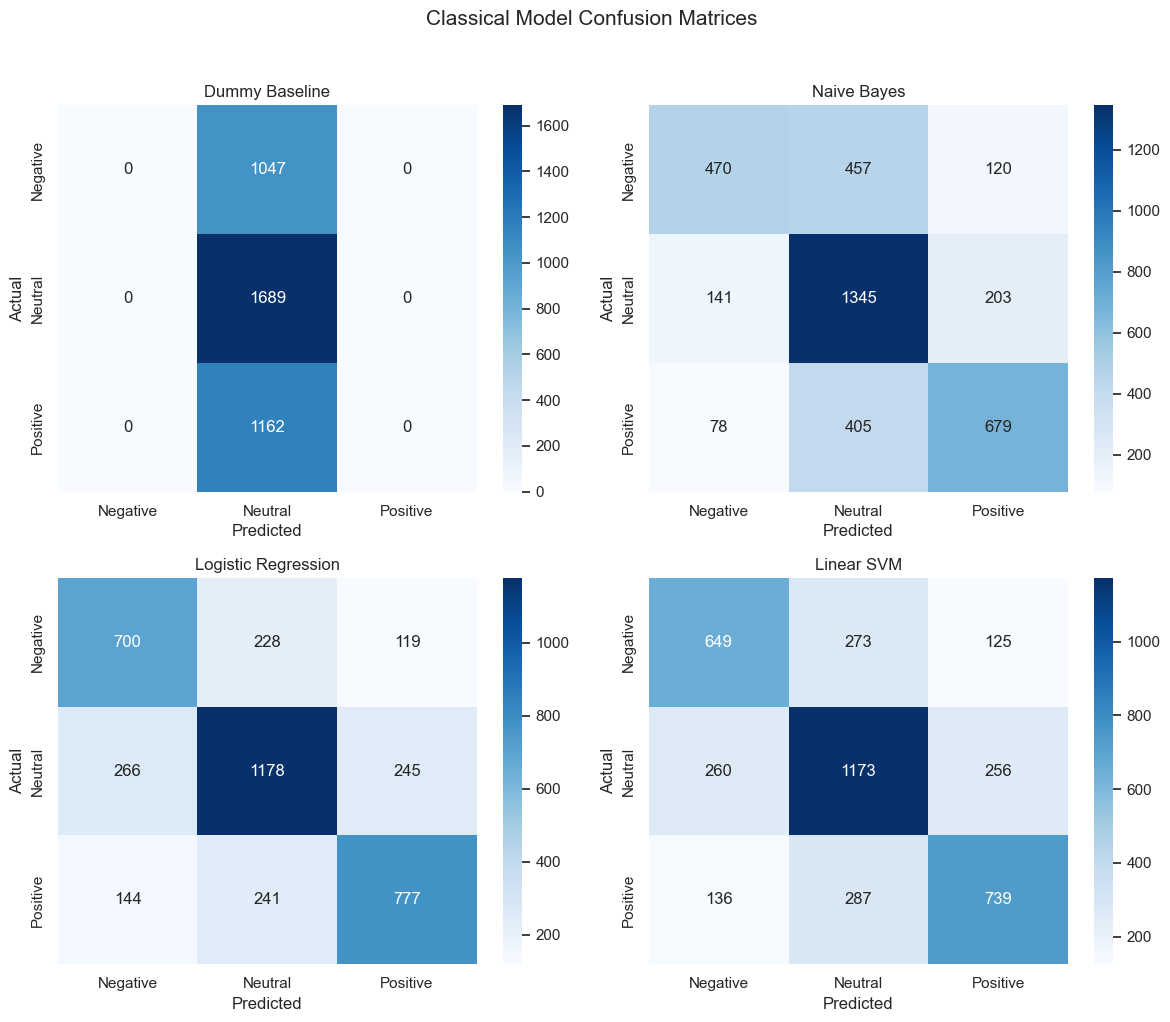

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for axis, (name, matrix) in zip(axes.ravel(), confusion_matrices.items()):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        ax=axis,
    )
    axis.set_title(name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

plt.suptitle("Classical Model Confusion Matrices", y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig(IMAGES / "06_classical_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Save the selected model and reproducible results

In [10]:
selected_model = models[best_classical_name]

joblib.dump(selected_model, MODELS / "best_classical_model.joblib")
validation_results.to_csv(RESULTS / "classical_validation_results.csv", index=False)
test_results.to_csv(RESULTS / "classical_test_results.csv", index=False)
prediction_table.to_csv(RESULTS / "classical_test_predictions.csv", index=False)

(RESULTS / "best_classical_model.txt").write_text(best_classical_name, encoding="utf-8")

print("Saved selected model:", MODELS / "best_classical_model.joblib")
print("Selected model:", best_classical_name)

Saved selected model: E:\AssDS\Project\models\best_classical_model.joblib
Selected model: Logistic Regression


## Conclusion

The dummy result is the minimum benchmark. The selected TF-IDF classifier was
chosen using validation macro-F1, not the test result. The same fixed test set is
used later for comparison with the BiLSTM and transformer.